Chuẩn bị: đọc dữ liệu

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

print("Lê Anh Pha - 6451071056")

data = pd.read_csv('mushrooms.csv')      # sửa tên file cho đúng với file bạn tải
print(data.shape)                        # thường là (8124, 23)
print(data['class'].value_counts())
data.head()

Lê Anh Pha - 6451071056
(8124, 23)
class
e    4208
p    3916
Name: count, dtype: int64


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


Câu 4: Tách thuộc tính và nhãn

In [2]:
print("Lê Anh Pha - 6451071056")

features = data.drop('class', axis=1)
labels = data['class']
print(features.shape, labels.shape)      # (8124, 22) (8124,)

Lê Anh Pha - 6451071056
(8124, 22) (8124,)


Câu 5: Chuyển sang one-hot

In [3]:
print("Lê Anh Pha - 6451071056")

cat_cols = features.select_dtypes(exclude=['int64', 'float64']).columns
print("Số cột cần one-hot:", len(cat_cols))      # cả 22 cột

features_onehot = pd.get_dummies(features, columns=cat_cols)
print(features_onehot.shape)                     # thường khoảng (8124, 117)
features_onehot.head()

Lê Anh Pha - 6451071056
Số cột cần one-hot: 22
(8124, 117)


,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,False,False,False,False,False,True,False,False,True,False,...,True,False,False,False,False,False,False,False,True,False
1,False,False,False,False,False,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
2,True,False,False,False,False,False,False,False,True,False,...,False,False,False,False,False,False,True,False,False,False
3,False,False,False,False,False,True,False,False,False,True,...,True,False,False,False,False,False,False,False,True,False
4,False,False,False,False,False,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False


Câu 6: Chia 70% huấn luyện, 30% kiểm thử

In [4]:
print("Lê Anh Pha - 6451071056")

X_train, X_test, y_train, y_test = train_test_split(features_onehot, labels, test_size=0.3, random_state=42)
print(X_train.shape, X_test.shape)               # (5686, ...) (2438, ...)

Lê Anh Pha - 6451071056
(5686, 117) (2438, 117)


Câu 7: Cây ID3

Lê Anh Pha - 6451071056
Accuracy: 1.0
Report:
               precision    recall  f1-score   support

           e       1.00      1.00      1.00      1257
           p       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438



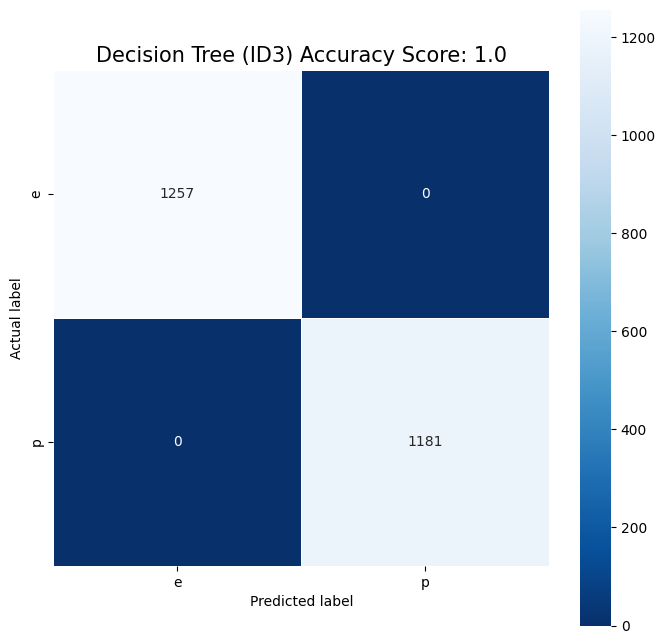

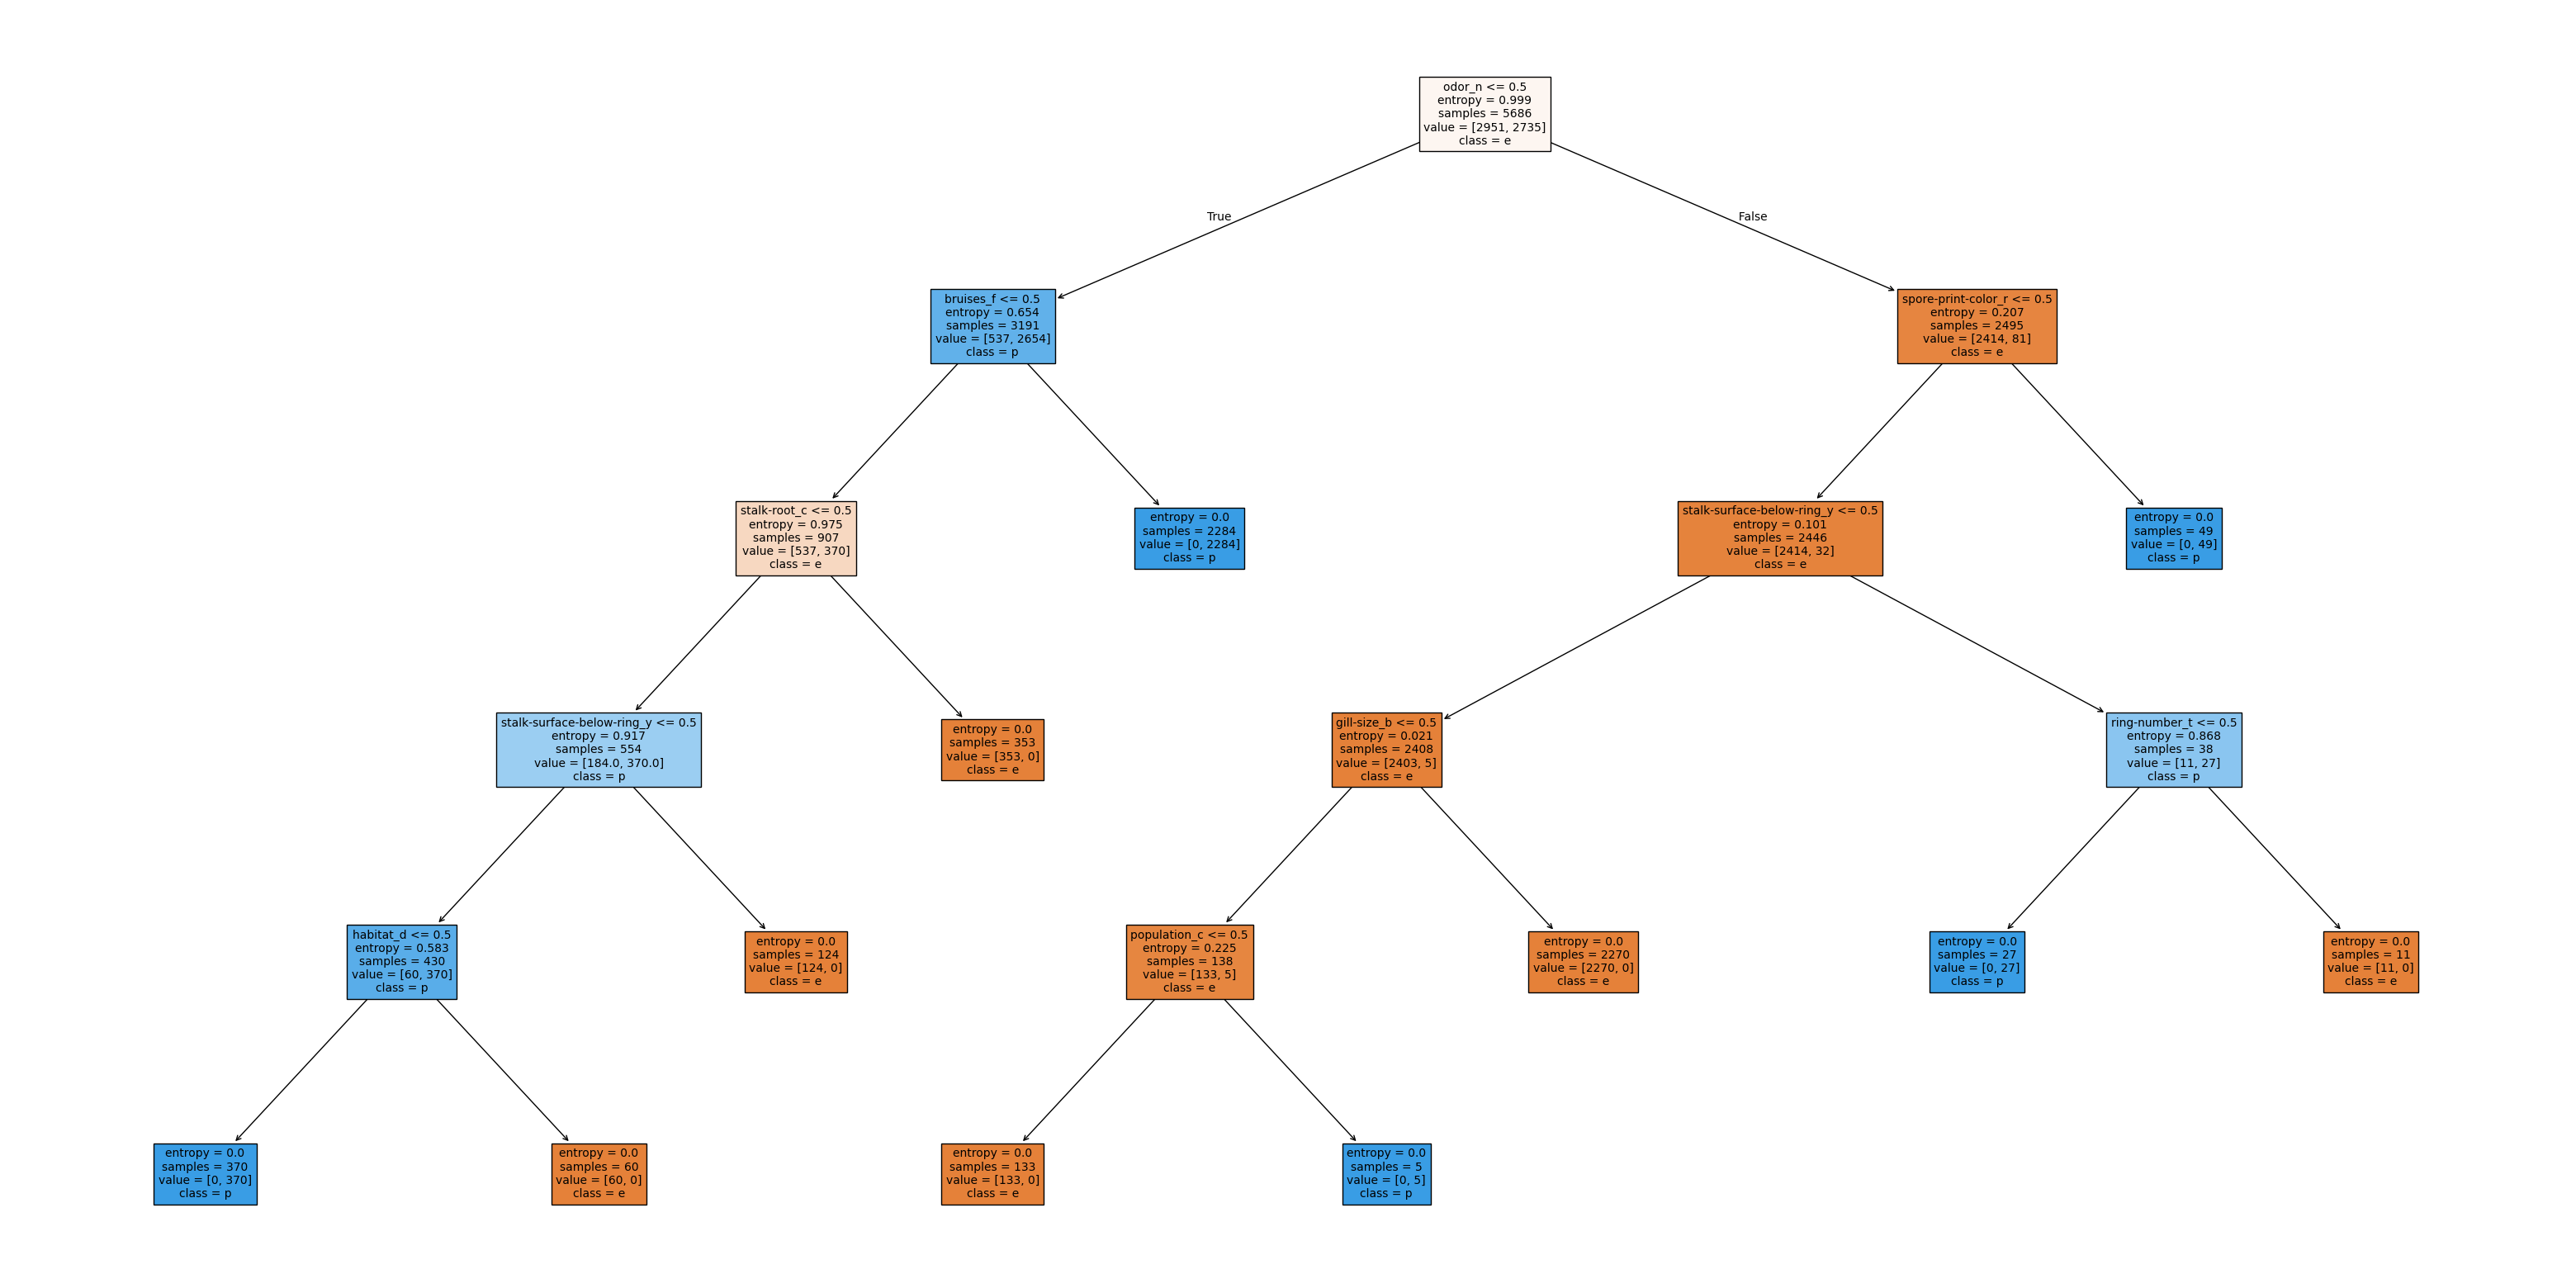

In [5]:
print("Lê Anh Pha - 6451071056")

clf = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
clf.fit(X_train, y_train)

tree_pred = clf.predict(X_test)
tree_score = metrics.accuracy_score(y_test, tree_pred)
print("Accuracy:", tree_score)
print("Report:\n", metrics.classification_report(y_test, tree_pred, zero_division=0))

tree_cm = metrics.confusion_matrix(y_test, tree_pred)
plt.figure(figsize=(8, 8))
sns.heatmap(tree_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Blues_r',
            xticklabels=clf.classes_, yticklabels=clf.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title('Decision Tree (ID3) Accuracy Score: {0}'.format(tree_score), size=15)
plt.show()

fig, ax = plt.subplots(figsize=(40, 20))
tree.plot_tree(clf, filled=True, fontsize=10, feature_names=X_train.columns, class_names=list(clf.classes_))
plt.savefig('decision_tree_id3', dpi=100)
plt.show()

Câu 8: Cây CART

Lê Anh Pha - 6451071056
Accuracy: 1.0
Report:
               precision    recall  f1-score   support

           e       1.00      1.00      1.00      1257
           p       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438



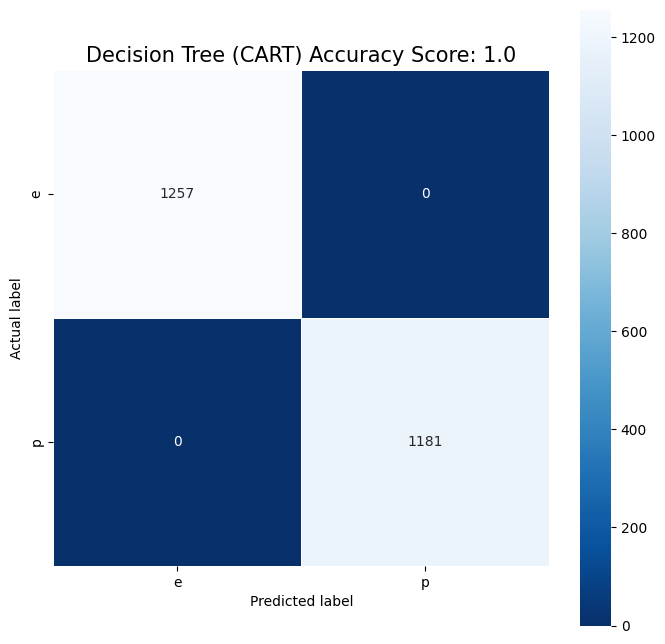

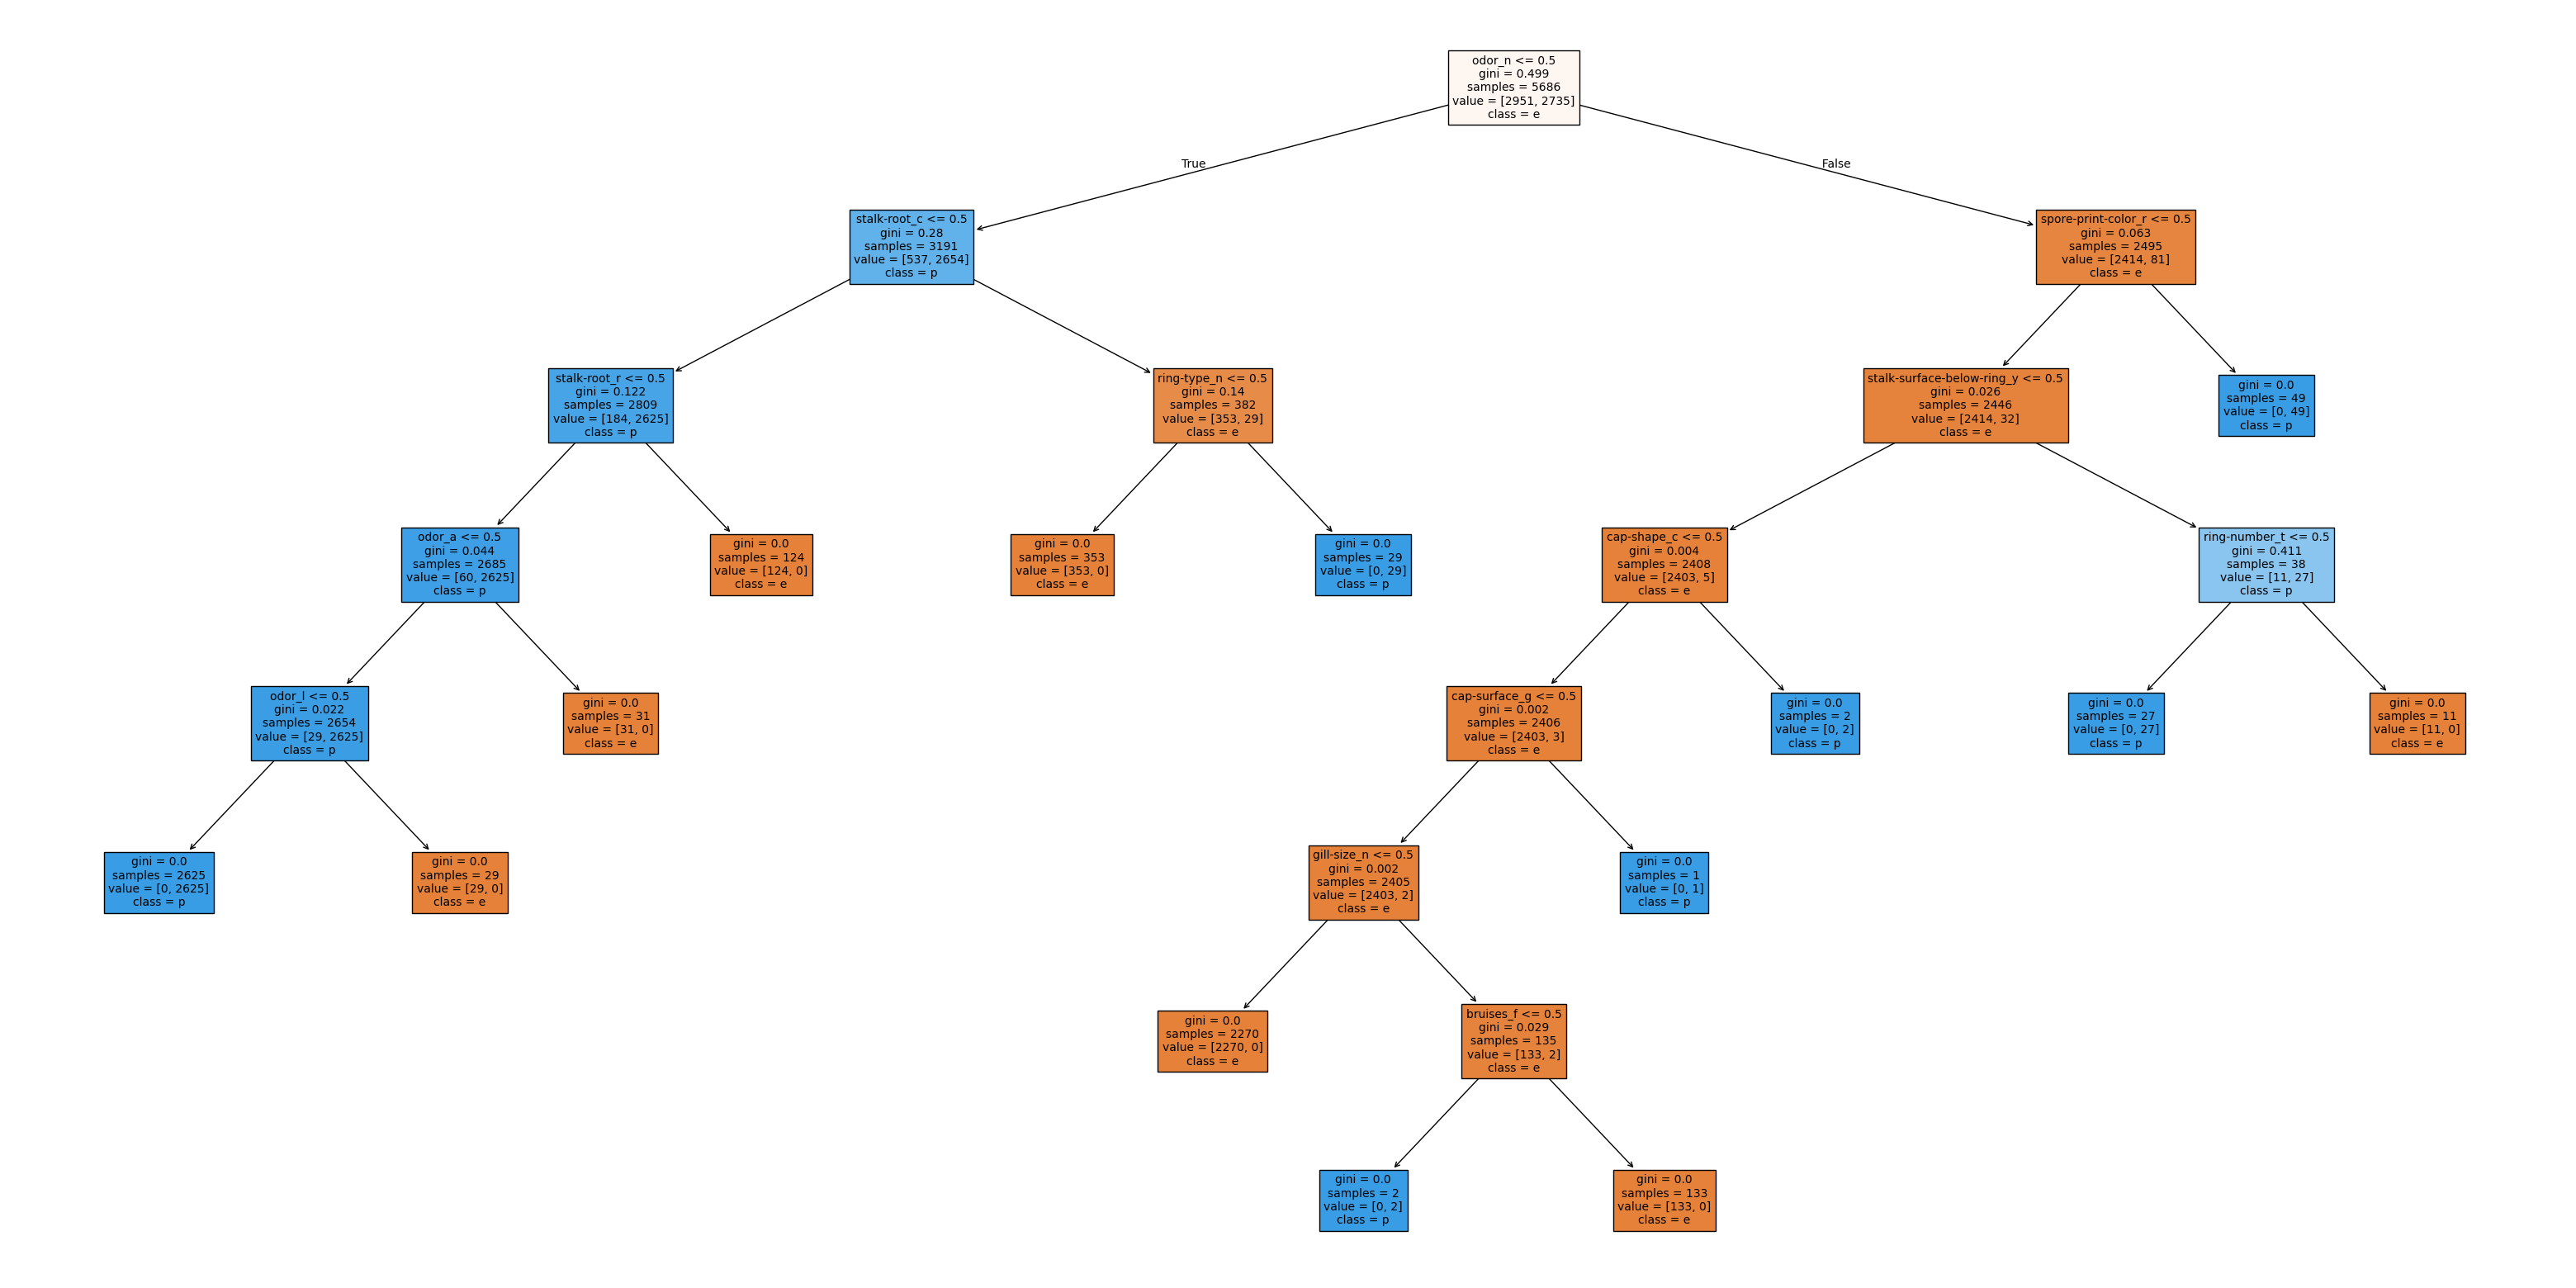

In [6]:
print("Lê Anh Pha - 6451071056")

clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
clf_cart.fit(X_train, y_train)

cart_pred = clf_cart.predict(X_test)
cart_score = metrics.accuracy_score(y_test, cart_pred)
print("Accuracy:", cart_score)
print("Report:\n", metrics.classification_report(y_test, cart_pred, zero_division=0))

cart_cm = metrics.confusion_matrix(y_test, cart_pred)
plt.figure(figsize=(8, 8))
sns.heatmap(cart_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Blues_r',
            xticklabels=clf_cart.classes_, yticklabels=clf_cart.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title('Decision Tree (CART) Accuracy Score: {0}'.format(cart_score), size=15)
plt.show()

fig, ax = plt.subplots(figsize=(40, 20))
tree.plot_tree(clf_cart, filled=True, fontsize=10, feature_names=X_train.columns, class_names=list(clf_cart.classes_))
plt.savefig('decision_tree_cart', dpi=100)
plt.show()

Câu 9: Naive Bayes

Lê Anh Pha - 6451071056
Accuracy: 0.9643150123051681
Report:
               precision    recall  f1-score   support

           e       1.00      0.93      0.96      1257
           p       0.93      1.00      0.96      1181

    accuracy                           0.96      2438
   macro avg       0.97      0.97      0.96      2438
weighted avg       0.97      0.96      0.96      2438



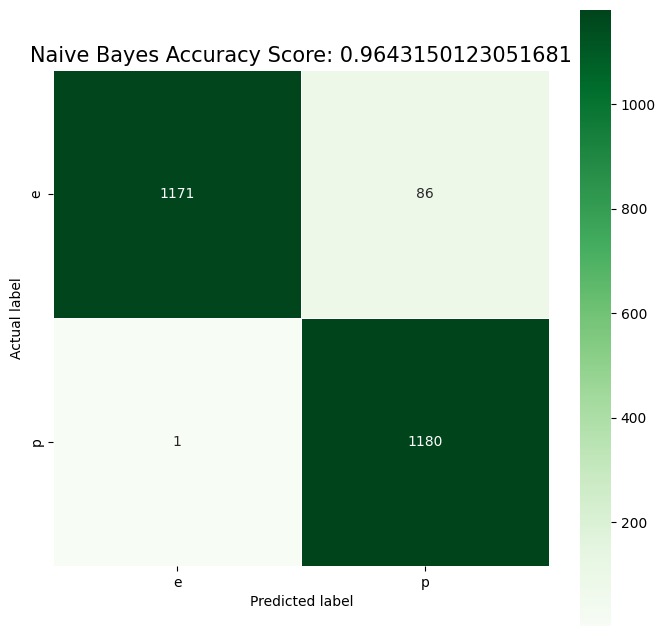

In [7]:
print("Lê Anh Pha - 6451071056")

gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print("Accuracy:", bayes_score)
print("Report:\n", metrics.classification_report(y_test, bayes_pred, zero_division=0))

bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)
plt.figure(figsize=(8, 8))
sns.heatmap(bayes_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Greens',
            xticklabels=gnb.classes_, yticklabels=gnb.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title('Naive Bayes Accuracy Score: {0}'.format(bayes_score), size=15)
plt.show()

Câu 10: So sánh các mô hình

In [8]:
print("Lê Anh Pha - 6451071056")

preds = {'ID3 (entropy)': tree_pred, 'CART (gini)': cart_pred, 'Naive Bayes': bayes_pred}
summary = pd.DataFrame({
    'Mô hình': list(preds.keys()),
    'Accuracy': [metrics.accuracy_score(y_test, p) for p in preds.values()],
    'Precision (p)': [metrics.precision_score(y_test, p, pos_label='p', zero_division=0) for p in preds.values()],
    'Recall (p)': [metrics.recall_score(y_test, p, pos_label='p', zero_division=0) for p in preds.values()],
    'F1 (p)': [metrics.f1_score(y_test, p, pos_label='p', zero_division=0) for p in preds.values()],
})
summary

Lê Anh Pha - 6451071056


,Mô hình,Accuracy,Precision (p),Recall (p),F1 (p)
0,ID3 (entropy),1.000000,1.00000,1.000000,1.000000
1,CART (gini),1.000000,1.00000,1.000000,1.000000
2,Naive Bayes,0.964315,0.93207,0.999153,0.964446
